# WEEK 2 — LAB 1A: Sampling, Aliasing and Quantization

**Name:** BARAKA MARTIN MDEKA
**Registration Number:** 240242436939
**Date:** 25/11/2026


## Pre-lab preparation
**Manual §1.2; Example 1.1**

1. A 7 kHz tone sampled at 10 kHz appears at **3 kHz**, since the Nyquist frequency is 5 kHz and the folded frequency is |7−10|=3 kHz.
2. For an 8-bit quantizer with ±1 V range: Δ = 2/256 = **0.0078125 V**. Full-scale sinusoidal SQNR ≈ 6.02(8)+1.76 = **49.92 dB**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
import os
plt.rcParams['figure.figsize'] = (9, 3.5)
plt.rcParams['axes.grid'] = True

## Task 2.1 — Aliasing of a sinusoid
The input tone is 7 Hz. Compare the dense-time cosine with its samples for four sampling rates and record the predicted alias frequency.

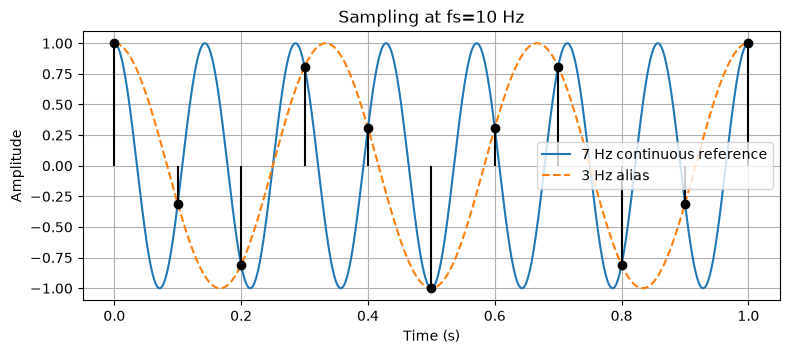

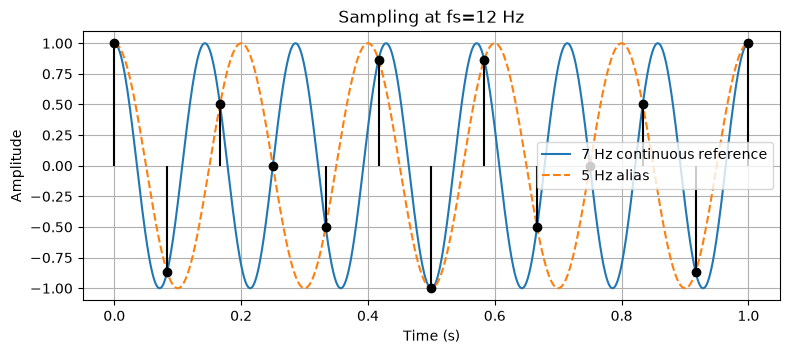

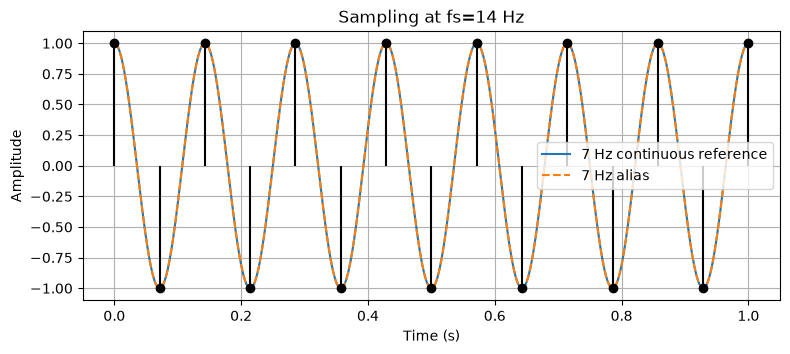

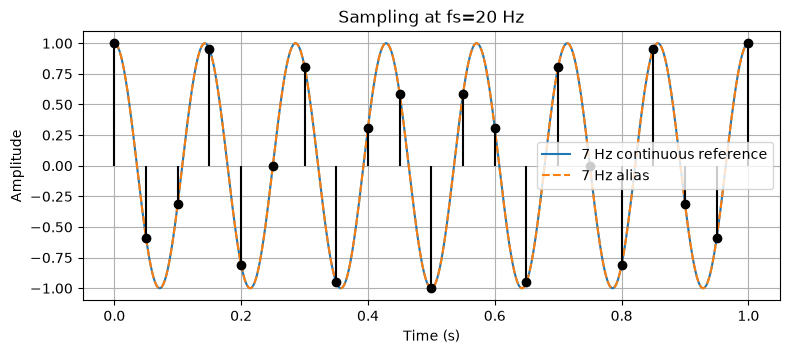

fs (Hz) | Nyquist (Hz) | alias (Hz)
   10.0 |          5.0 |       3.0
   12.0 |          6.0 |       5.0
   14.0 |          7.0 |       7.0
   20.0 |         10.0 |       7.0


In [2]:
f0 = 7.0
sampling_rates = [10.0, 12.0, 14.0, 20.0]
alias_rows = []
for fs in sampling_rates:
    t = np.linspace(0, 1, 3000)
    n = np.arange(0, int(fs)+1)
    tn = n/fs
    # Fold the frequency into the Nyquist interval.
    fa = abs(f0 - fs*round(f0/fs))
    alias_rows.append((fs, fs/2, fa))
    plt.figure()
    plt.plot(t, np.cos(2*np.pi*f0*t), label=f'{f0:g} Hz continuous reference')
    plt.plot(t, np.cos(2*np.pi*fa*t), '--', label=f'{fa:g} Hz alias')
    plt.stem(tn, np.cos(2*np.pi*f0*tn), linefmt='k-', markerfmt='ko', basefmt=' ')
    plt.title(f'Sampling at fs={fs:g} Hz')
    plt.xlabel('Time (s)'); plt.ylabel('Amplitude'); plt.legend(); plt.show()
print('fs (Hz) | Nyquist (Hz) | alias (Hz)')
for row in alias_rows: print(f'{row[0]:7.1f} | {row[1]:12.1f} | {row[2]:9.1f}')

**Observation:** at fs=10 Hz the 7 Hz tone aliases to 3 Hz. At fs=14 Hz it lies exactly at Nyquist (7 Hz); at fs=20 Hz it is below Nyquist and is represented without folding.

## Task 2.2 — Hear aliasing
Load your Week 1 recording as `my_voice.wav` in the notebook folder. If it is absent, a chirp from 200 Hz to 15 kHz is generated. Compare naïve sample dropping with anti-aliased decimation.

Original sampling rate: 44100 Hz
k=2, new fs=22050 Hz, naive length=66150, filtered length=66150
k=4, new fs=11025 Hz, naive length=33075, filtered length=33075
k=8, new fs=5512 Hz, naive length=16538, filtered length=16538


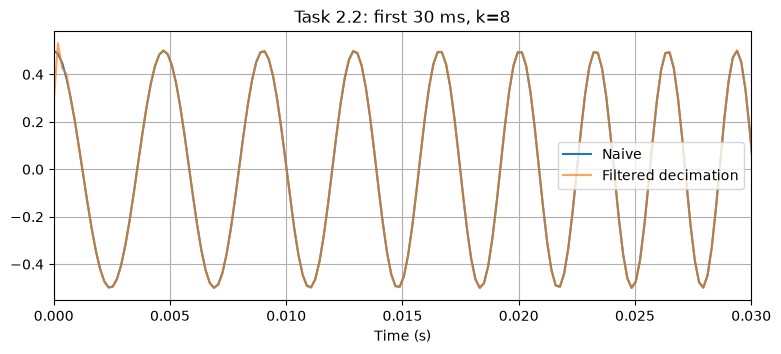

In [3]:
fname = 'my_voice.wav'
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.astype(float)
    if x.ndim > 1: x = x.mean(axis=1)
    x /= max(np.max(np.abs(x)), 1)
else:
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5*signal.chirp(t, 200, 3, 15000)
print('Original sampling rate:', fs, 'Hz')
for k in [2, 4, 8]:
    naive = x[::k]
    proper = signal.decimate(x, k, ftype='fir')
    new_fs = fs//k
    print(f'k={k}, new fs={new_fs} Hz, naive length={len(naive)}, filtered length={len(proper)}')
    # In Jupyter, uncomment to listen:
    # from IPython.display import Audio, display
    # display(Audio(naive, rate=new_fs))
    # display(Audio(proper, rate=new_fs))
    if k == 8:
        plt.figure()
        plt.plot(np.arange(len(naive))/new_fs, naive, label='Naive')
        plt.plot(np.arange(len(proper))/new_fs, proper, alpha=.7, label='Filtered decimation')
        plt.xlim(0, min(.03, len(naive)/new_fs)); plt.legend()
        plt.title('Task 2.2: first 30 ms, k=8'); plt.xlabel('Time (s)'); plt.show()

**Listening notes to complete:** describe the k=8 naïve version (aliasing/distortion) and filtered version (reduced high-frequency foldover). Actual listening observations depend on the recording and should be written after listening.

## Task 2.3 — A uniform quantizer
Quantize a 300 Hz sinusoid to 3 bits and plot the original, quantized signal and quantization error.

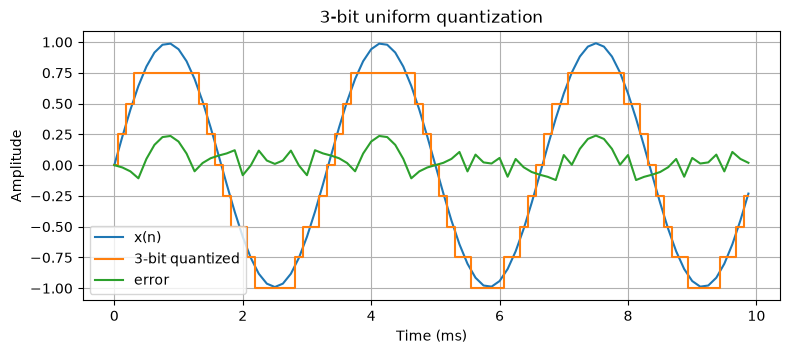

Quantization step Δ = 0.25


In [4]:
def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale-delta)

fs_q = 8000
tq = np.arange(0, .01, 1/fs_q)
xq_in = .99*np.sin(2*np.pi*300*tq)
xq_out = quantize(xq_in, 3)
plt.plot(tq*1e3, xq_in, label='x(n)')
plt.step(tq*1e3, xq_out, where='mid', label='3-bit quantized')
plt.plot(tq*1e3, xq_in-xq_out, label='error')
plt.xlabel('Time (ms)'); plt.ylabel('Amplitude'); plt.title('3-bit uniform quantization')
plt.legend(); plt.show()
print('Quantization step Δ =', 2/2**3)

## 
Task 2.4 — Verify the 6 dB-per-bit rule
Measure SQNR for B = 2, 4, …, 16 and compare with 6.02B + 1.76 dB.

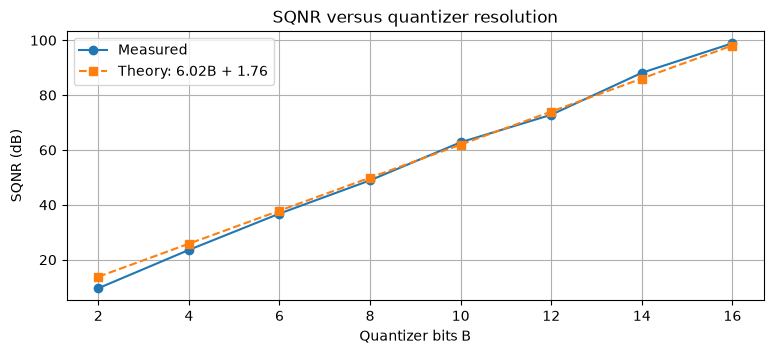

 2 bits: measured=   9.60 dB, theoretical=  13.80 dB
 4 bits: measured=  23.58 dB, theoretical=  25.84 dB
 6 bits: measured=  36.81 dB, theoretical=  37.88 dB
 8 bits: measured=  48.93 dB, theoretical=  49.92 dB
10 bits: measured=  62.81 dB, theoretical=  61.96 dB
12 bits: measured=  72.84 dB, theoretical=  74.00 dB
14 bits: measured=  88.13 dB, theoretical=  86.04 dB
16 bits: measured=  98.91 dB, theoretical=  98.08 dB


In [5]:


bits = np.arange(2, 17, 2)
measured, theoretical = [], 6.02*bits + 1.76
for B in bits:
    qx = quantize(xq_in, int(B))
    err = xq_in-qx
    measured.append(10*np.log10(np.sum(xq_in**2)/np.sum(err**2)))
plt.plot(bits, measured, 'o-', label='Measured')
plt.plot(bits, theoretical, 's--', label='Theory: 6.02B + 1.76')
plt.xlabel('Quantizer bits B'); plt.ylabel('SQNR (dB)')
plt.title('SQNR versus quantizer resolution'); plt.legend(); plt.show()
for B, m, th in zip(bits, measured, theoretical):
    print(f'{B:2d} bits: measured={m:7.2f} dB, theoretical={th:7.2f} dB')

## Task 2.5 — Quantize your voice
Quantize the loaded/fallback recording to 4, 8 and 12 bits, calculate SQNR, and optionally listen to each version.

In [6]:
# Use the signal x loaded in Task 2.2. Normalize to the quantizer's ±1 range.
x_voice = x / max(np.max(np.abs(x)), 1e-12)
voice_results = {}
for B in [4, 8, 12]:
    qv = quantize(x_voice, B)
    e = x_voice-qv
    sqnr = 10*np.log10(np.sum(x_voice**2)/max(np.sum(e**2), 1e-30))
    voice_results[B] = (qv, sqnr)
    print(f'{B}-bit voice SQNR: {sqnr:.2f} dB')
    # Uncomment in Jupyter to listen:
    # from IPython.display import Audio, display
    # display(Audio(qv, rate=fs))

4-bit voice SQNR: 23.25 dB
8-bit voice SQNR: 49.10 dB
12-bit voice SQNR: 73.81 dB


## Analysis questions — suggested answers
1. With fs=10 Hz, Nyquist is 5 Hz. A 7 Hz component folds around fs/2 to |7−10|=3 Hz; sampled values are indistinguishable from a 3 Hz sinusoid. A frequency-axis sketch should show replicas spaced by 10 Hz and the 7 Hz component reflected to 3 Hz.
2. Naïve decimation discards samples without first removing frequencies above the new Nyquist limit. Those components fold into the retained band and overlap desired frequencies; after this information is mixed, it cannot generally be separated by later filtering.
3. One extra bit halves Δ and reduces quantization-noise power by about four, so SQNR improves by approximately **6.02 dB per bit**. Compare the measured curve with the theoretical line; deviations occur from finite records, non-full-scale/non-ideal signal statistics and quantizer implementation.
4. The signal changes no faster than 0.1 °C/s. A reasonable minimum sample rate from a simple tracking argument is greater than 0.2 samples/s; choose a practical margin such as **1 sample/s**. A 0–100 °C range at 0.01 °C resolution needs 10001 distinguishable levels, so B ≥ ceil(log2(10001)) = **14 bits**. This is a design suggestion; sensor noise and dynamics may require a higher rate/resolution.

## Checkpoint and submission
- Show the alias table from Task 2.1 and the SQNR graph from Task 2.4.
- Confirm Tasks 2.1–2.5, alias table, SQNR graph, listening observations and all answers are present.
- Save as `COU07506_Week02_<RegNo>.ipynb` and submit to DIT-eLMS.

**AI-use statement:** This notebook was prepared with AI assistance for code structuring and explanatory guidance. Verify results, run all cells, and disclose assistance according to your instructor's rules.

**Student listening observations:** [Complete after listening.]